<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [LiDAR analysis](https://github.com/Query-farm/vgi-lidar)

Classified point-cloud heights and vegetation clearance around power lines.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-lidar/blob/main/notebooks/01_height_support_changes_the_population.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-lidar/blob/main/notebooks/README.md)


## 01 · A higher canopy statistic does not imply growth

What changes when we require a closer ground return before estimating a tree's height? We will hold a classified point cloud fixed, tighten that support radius, and watch the population behind a height percentile change. A separate conductor-clearance calculation provides a control: it measures absolute 3D distance and does not normalize to ground.

**This is a constructed scientific fixture, not a surveyed site.** The pinned worker packages `classified.laz`, a 29-return cloud with 25 flat-ground returns, two building returns and two vegetation returns, plus a site polygon and a 3D conductor. There are no observation dates, live services or external credentials. The real LAS/LAZ, nearest-ground and segment-distance implementation executes through VGI; no result is fabricated if it fails.

### Choose how close ground support must be

`GROUND_RADIUS_M` is a finite horizontal distance from 2 to 25 in metres. This authored comparison restricts the radius to 2–25 m; the worker itself accepts other positive distances. Default **25 m** accepts nearby class-2 ground support; the separate experiment uses **2 m**. The comparison always retains a fixed 25 m reference. Building and vegetation heights are point Z minus the nearest usable ground return's Z, only when that return is within the inclusive radius.

Inputs use **EPSG:32618**, X/Y order in metres. Cloud and conductor Z share a synthetic absolute-metre datum: ground is 100 m and the conductor is 120 m. XY reprojection does not convert vertical datums. We fix the 5 m grid, 2 m canopy-height cutoff and a 3 m illustrative clearance screen. Restart Kernel → Run All after editing.

In [1]:
GROUND_RADIUS_M = 25.0  # metres; finite 2–25; experiment: 2.0

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.28":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.28"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime

check_runtime()

In [3]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme

if (
    type(GROUND_RADIUS_M) not in (int, float)
    or not np.isfinite(GROUND_RADIUS_M)
    or not 2 <= GROUND_RADIUS_M <= 25
):
    raise ValueError("GROUND_RADIUS_M must be a finite number from 2 to 25 metres.")
theme()
session = connect(globals())
SOURCE = "Source: bundled synthetic 29-return LAZ · EPSG:32618 / metre Z · vgi-lidar v0.1.0"
Path("artifacts").mkdir(exist_ok=True)

### Connect to the released worker

The literal **v0.1.0** Git-tag launcher starts an isolated Python 3.13 worker. The release owns its scientific and SDK dependency constraints: no old constraints file, extra overrides or local source checkout is needed. The notebook installs the shared base package, and the locked local environment adds `[runner]`. First use downloads Git/package dependencies and VGI; analysis thereafter uses bundled synthetic data. The shared SQL connection starts with an empty temporary secret directory and disables persistent secrets.

`main` contains the point-cloud analysis: `height_metrics` and `vegetation_clearance`.

### Keep heights and clearance as separate measurements

`demo://classified.laz` resolves inside the installed worker package. Two inline `VALUES` rows supply the site polygon and the 3D conductor line in the same datum, as WKB built by `ST_AsWKB('…'::GEOMETRY)`. Three analysis calls materialize reference heights, selected heights and a fixed **12 m** conductor-distance envelope. Both vegetation returns fall inside that envelope. Later SQL applies the illustrative **3 m** screen locally.

`max_points` bounds the entire loaded tile; grid, segment and distance-evaluation caps reject excessive work rather than silently truncating it. These are computational bounds, not SQL row limits.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'lidar' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-lidar@v0.1.0 vgi-lidar-worker');
CREATE TABLE site AS SELECT 'site' AS feature_id, ST_AsWKB(
 'POLYGON ((499995 4099995, 500045 4099995, 500045 4100045, 499995 4100045, 499995 4099995))'::GEOMETRY) AS geometry_wkb;
CREATE TABLE conductor AS SELECT 'line' AS feature_id, ST_AsWKB(
 'LINESTRING Z (500025 4100030 120, 500040 4100030 120)'::GEOMETRY) AS geometry_wkb;
CREATE TABLE reference_metrics AS
SELECT * FROM lidar.main.height_metrics((SELECT * FROM site),
 path := 'demo://classified.laz', geometry_crs := 'EPSG:32618', z_scale_to_m := 1.0,
 ground_radius_m := 25.0, grid_size_m := 5.0, canopy_height_m := 2.0,
 max_points := 100, max_grid_cells := 100);
CREATE TABLE selected_metrics AS
SELECT * FROM lidar.main.height_metrics((SELECT * FROM site),
 path := 'demo://classified.laz', geometry_crs := 'EPSG:32618', z_scale_to_m := 1.0,
 ground_radius_m := {{GROUND_RADIUS_M}}, grid_size_m := 5.0, canopy_height_m := 2.0,
 max_points := 100, max_grid_cells := 100);
CREATE TABLE clearance_envelope AS
SELECT * FROM lidar.main.vegetation_clearance((SELECT * FROM conductor),
 path := 'demo://classified.laz', geometry_crs := 'EPSG:32618', z_scale_to_m := 1.0,
 clearance_m := 12.0, max_points := 100, max_segments := 10,
 max_distance_evaluations := 100);

,Count


### Reconcile the population before comparing the percentile

A polygon with returns can still lack support for some building or vegetation heights. Those returns are counted in `unsupported_points` and excluded from height percentiles. A higher percentile after exclusion can be a population effect.

The site is a 50 × 50 m square with 100 intersecting 5 × 5 m cells. Only observed cells participate in the support calculation; only observed cells with **every contained point ground-supported** participate in canopy cover. SQL reconstructs the corresponding integer denominators for this exact fixture. The resulting cover fraction is not wall-to-wall canopy area.

In [5]:
%%sql
CREATE TABLE comparison AS
WITH scenarios AS (
 SELECT 'Reference · 25 m' scenario,* FROM reference_metrics
 UNION ALL SELECT 'Selected' scenario,* FROM selected_metrics)
SELECT *,round(100*observed_cell_fraction)::INTEGER observed_cells,
 round(100*observed_cell_fraction*ground_supported_cell_fraction)::INTEGER supported_cells,
 round(100*observed_cell_fraction*ground_supported_cell_fraction*canopy_cover_fraction)::INTEGER canopy_cells
FROM scenarios;

,Count


In [6]:
%%sql metrics <<
SELECT scenario,point_count,building_points,building_p95_m,building_max_m,
 vegetation_points,canopy_p95_m,canopy_max_m,unsupported_points,status,
 observed_cells,supported_cells,canopy_cells,canopy_cover_fraction
FROM comparison ORDER BY scenario;

In [7]:
%%sql checks <<
SELECT
 (SELECT count(*)-count(DISTINCT feature_id) FROM selected_metrics) duplicate_keys,
 (SELECT count(*) FROM selected_metrics s JOIN reference_metrics r USING(feature_id)
  WHERE s.point_count<>r.point_count OR s.observed_cell_fraction<>r.observed_cell_fraction) changed_observations,
 count(*) FILTER(WHERE building_points+vegetation_points+unsupported_points<>4) population_mismatches,
 count(*) FILTER(WHERE building_p95_m>building_max_m OR canopy_p95_m>canopy_max_m) percentile_mismatches,
 count(*) FILTER(WHERE observed_cells<>26 OR supported_cells>observed_cells OR canopy_cells>supported_cells) cell_mismatches,
 count(*) FILTER(WHERE abs(canopy_cover_fraction-canopy_cells::DOUBLE/supported_cells)>1e-12) fraction_mismatches,
 count(*) FILTER(WHERE (building_points=0)<>(building_p95_m IS NULL)
  OR (vegetation_points=0)<>(canopy_p95_m IS NULL)) missing_height_mismatches,
 count(*) FILTER(WHERE status<>CASE WHEN unsupported_points>0 THEN 'partial_ground' ELSE 'ok' END) status_mismatches,
 (SELECT count(*) FROM clearance_envelope
  WHERE abs(clearance_m-sqrt(pow(x-nearest_x,2)+pow(y-nearest_y,2)+pow(z_m-nearest_z_m,2)))>1e-12
   OR clearance_m>12 OR cloud_crs<>'EPSG:32618') distance_mismatches
FROM comparison;

In [8]:
%%sql population <<
SELECT (SELECT count(*) FROM clearance_envelope) AS clearance_rows,
 (SELECT count(*) FROM comparison WHERE cloud_crs<>'EPSG:32618') AS crs_mismatches;

In [9]:
%%sql reference <<
SELECT * FROM reference_metrics ORDER BY feature_id;

In [10]:
%%sql clearance <<
SELECT * FROM clearance_envelope ORDER BY point_index;

In [11]:
display(checks)
assert checks.iloc[0].eq(0).all()
display(population)
assert population.clearance_rows.iloc[0] == 2
assert population.crs_mismatches.iloc[0] == 0
fingerprint = hashlib.sha256(
    (reference.to_json(orient="records") + clearance.to_json(orient="records")).encode()
).hexdigest()
prose(
    f"Nine SQL consistency checks and the CRS/population controls pass. Reference metrics plus the fixed clearance envelope have fingerprint `{fingerprint}`; changing ground support must leave that control unchanged. These checks establish behavior on a known fixture, not survey accuracy."
)

,duplicate_keys,changed_observations,population_mismatches,percentile_mismatches,cell_mismatches,fraction_mismatches,missing_height_mismatches,status_mismatches,distance_mismatches
0,0,0,0,0,0,0,0,0,0


,clearance_rows,crs_mismatches
0,2,0


Nine SQL consistency checks and the CRS/population controls pass. Reference metrics plus the fixed clearance envelope have fingerprint `962635dd242f3a806dac19989fd3f5e522f7c8286fced08f7a7b3d5e3c271c6a`; changing ground support must leave that control unchanged. These checks establish behavior on a known fixture, not survey accuracy.

,scenario,point_count,building_points,building_p95_m,building_max_m,vegetation_points,canopy_p95_m,canopy_max_m,unsupported_points,status,observed_cells,supported_cells,canopy_cells,canopy_cover_fraction
0,Reference · 25 m,29,2,11.9,12.0,2,17.6,18.0,0,ok,26,26,2,0.076923
1,Selected,29,2,11.9,12.0,2,17.6,18.0,0,ok,26,26,2,0.076923


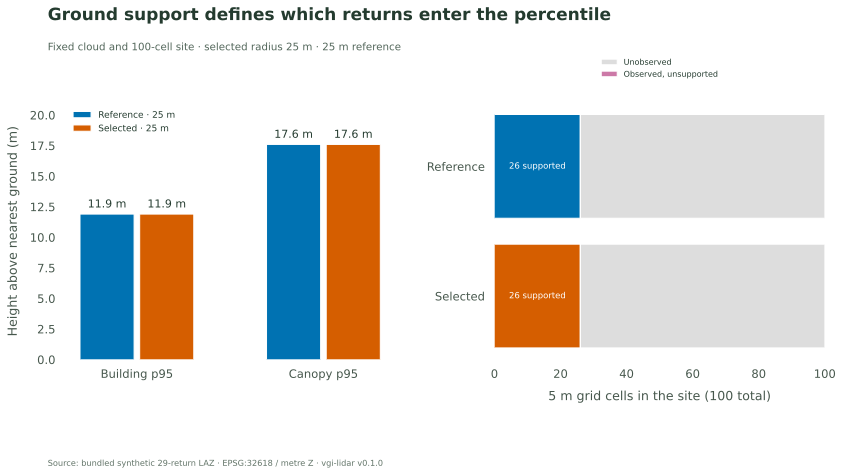

At **25 m**, the selected canopy p95 is **17.6 m**, versus **17.6 m** in the reference. Supported vegetation returns are **2 versus 2**; unsupported building/vegetation returns are **0**. Both still observe **26/100 cells**. Canopy cover is **2/26 = 7.7%** of supported observed cells, not 7.7% of the entire site.

In [12]:
display(metrics)
ref = metrics.iloc[0]
sel = metrics.iloc[1]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 7))
x = np.arange(2)
for offset, row, color, label in [
    (-0.16, ref, "#0072b2", "Reference · 25 m"),
    (0.16, sel, "#d55e00", f"Selected · {GROUND_RADIUS_M:g} m"),
]:
    bars = a.bar(
        x + offset, [row.building_p95_m, row.canopy_p95_m], width=0.29, color=color, label=label
    )
    a.bar_label(bars, fmt="%.1f m", padding=4)
a.set(
    xticks=x,
    xticklabels=["Building p95", "Canopy p95"],
    ylim=(0, 21),
    ylabel="Height above nearest ground (m)",
)
a.legend(fontsize=9, loc="upper left")
y = np.arange(2)
b.barh(y, [ref.supported_cells, sel.supported_cells], color=["#0072b2", "#d55e00"])
b.barh(
    y,
    [100 - ref.observed_cells, 100 - sel.observed_cells],
    left=[ref.observed_cells, sel.observed_cells],
    color="#dddddd",
    label="Unobserved",
)
b.barh(
    y,
    [ref.observed_cells - ref.supported_cells, sel.observed_cells - sel.supported_cells],
    left=[ref.supported_cells, sel.supported_cells],
    color="#cc79a7",
    label="Observed, unsupported",
)
for i, row in enumerate([ref, sel]):
    b.text(
        row.supported_cells / 2,
        i,
        f"{row.supported_cells} supported",
        ha="center",
        va="center",
        color="white",
        fontsize=8.5,
    )
b.set(
    yticks=y,
    yticklabels=["Reference", "Selected"],
    xlim=(0, 100),
    xlabel="5 m grid cells in the site (100 total)",
)
b.invert_yaxis()
b.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.20))

finish(
    fig,
    "Ground support defines which returns enter the percentile",
    f"Fixed cloud and 100-cell site · selected radius {GROUND_RADIUS_M:g} m · 25 m reference",
    SOURCE,
    name=f"height-support-{GROUND_RADIUS_M:g}",
)
prose(
    f"At **{GROUND_RADIUS_M:g} m**, the selected canopy p95 is **{sel.canopy_p95_m:.1f} m**, versus **{ref.canopy_p95_m:.1f} m** in the reference. Supported vegetation returns are **{sel.vegetation_points} versus {ref.vegetation_points}**; unsupported building/vegetation returns are **{sel.unsupported_points}**. Both still observe **{sel.observed_cells}/100 cells**. Canopy cover is **{sel.canopy_cells}/{sel.supported_cells} = {sel.canopy_cover_fraction:.1%}** of supported observed cells, not {sel.canopy_cover_fraction:.1%} of the entire site."
)

### Absolute clearance does not need a ground estimate

The worker measures the shortest Euclidean 3D distance from each vegetation return to the supplied conductor segments. This is a different quantity from height above ground. Here the line is horizontal at 120 m, both closest points lie directly above their returns, and the distance reduces to a vertical difference. The SQL reconstruction checks all three coordinate differences, so it does not assume that simplification for general conductors.

The fixed 12 m envelope supplies both returns for this view; the 3 m screen is just a local analytical choice. Neither its threshold nor an absence of selected returns establishes regulatory compliance, safety or complete vegetation detection.

In [13]:
%%sql distances <<
SELECT point_index,x-500000 AS local_easting_m,z_m,nearest_z_m,clearance_m,
 clearance_m<=3.0 AS inside_illustrative_screen
FROM clearance_envelope ORDER BY point_index;

,point_index,local_easting_m,z_m,nearest_z_m,clearance_m,inside_illustrative_screen
0,27,30.0,118.0,120.0,2.0,True
1,28,35.0,110.0,120.0,10.0,False


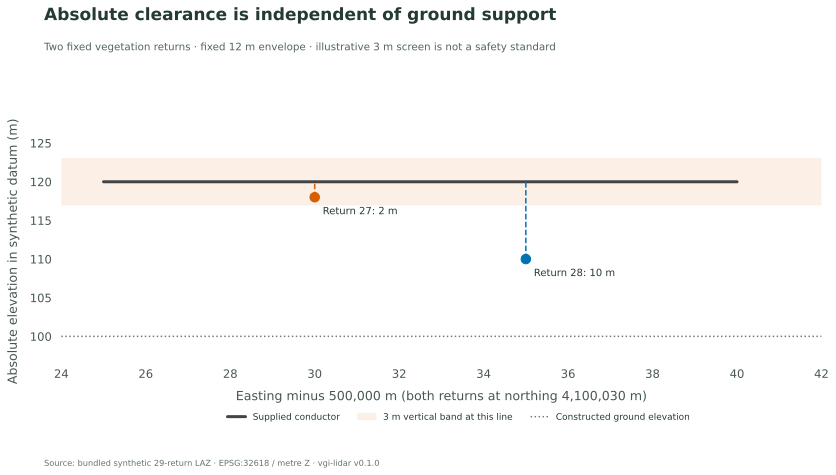

The 12 m envelope contains **2 vegetation returns**. **1** meets the illustrative 3 m screen; the nearest distance is **2 m**. These coordinates and distances are unchanged by `GROUND_RADIUS_M`. Tightening support can change the canopy summary while leaving this separate absolute-distance calculation intact.

In [14]:
display(distances)
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot([25, 40], [120, 120], color="#444444", linewidth=3, label="Supplied conductor")
ax.axhspan(117, 123, color="#d55e00", alpha=0.10, label="3 m vertical band at this line")
for row in distances.itertuples():
    color = "#d55e00" if row.inside_illustrative_screen else "#0072b2"
    ax.plot([row.local_easting_m] * 2, [row.z_m, row.nearest_z_m], color=color, linestyle="--")
    ax.scatter(row.local_easting_m, row.z_m, s=90, color=color, zorder=5)
    ax.annotate(
        f"Return {row.point_index}: {row.clearance_m:g} m",
        (row.local_easting_m, row.z_m),
        xytext=(8, -17),
        textcoords="offset points",
        fontsize=10,
    )
ax.axhline(100, color="#777777", linestyle=":", label="Constructed ground elevation")
ax.set(
    xlim=(24, 42),
    ylim=(97, 125),
    xlabel="Easting minus 500,000 m (both returns at northing 4,100,030 m)",
    ylabel="Absolute elevation in synthetic datum (m)",
)
fig.legend(loc="lower center", bbox_to_anchor=(0.55, 0.13), ncol=3, fontsize=9)

finish(
    fig,
    "Absolute clearance is independent of ground support",
    "Two fixed vegetation returns · fixed 12 m envelope · illustrative 3 m screen is not a safety standard",
    SOURCE,
    name="clearance-control",
)
selected = int(distances.inside_illustrative_screen.sum())
prose(
    f"The 12 m envelope contains **{len(distances)} vegetation returns**. **{selected}** meets the illustrative 3 m screen; the nearest distance is **{distances.clearance_m.min():g} m**. These coordinates and distances are unchanged by `GROUND_RADIUS_M`. Tightening support can change the canopy summary while leaving this separate absolute-distance calculation intact."
)

### Carry the denominator and datum into the next analysis

For a real classified tile, retain ground support, point counts, grid coverage and NULL/status fields alongside height percentiles. A percentile based on a changed population is not evidence of tree growth. Nearest-ground normalization may be unsuitable on steep terrain or with sparse/misclassified ground; a supported estimate is not a guarantee of accuracy.

The worker excludes noise classes 7/18 and withheld returns, uses vegetation classes 3/4/5 and building class 6, and performs no classification or conductor extraction. Clearance depends on supplied conductor geometry, positioning and a common vertical datum. Sparse samples cannot certify an empty or safe corridor.

**Try the separate 2 m experiment:** expect the lower vegetation return to lose ground support, canopy p95 to rise, and the unchanged clearance control to retain both distances. The README gives an output-isolated command, so the saved default remains reviewable.

In [15]:
audit = {
    "ground_radius_m": GROUND_RADIUS_M,
    "control_fingerprint": fingerprint,
    "reference": json.loads(reference.to_json(orient="records")),
    "metrics": json.loads(metrics.to_json(orient="records")),
    "clearance": json.loads(clearance.to_json(orient="records")),
    "checks": checks.iloc[0].to_dict(),
}
Path("artifacts/analysis-audit.json").write_text(json.dumps(audit, indent=2) + "\n")
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-lidar](https://github.com/Query-farm/vgi-lidar)
